### Step 1: Environment Setup
In this section, we import the core scientific computing, data manipulation, and visualization libraries required for our analysis.

Exploratory Data Analysis and Data Preprocessing of a Housing Prices Dataset

importing packages required for the project

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Loading the data set into the program

### Step 2: Data Loading
Here, we load our raw housing dataset from the CSV file into a pandas DataFrame to begin our analysis.

In [2]:
df=pd.read_csv("/content/housing_prices_regression.csv")

observing the data set

### Step 3: Initial Data Exploration
We inspect the structural info, first few rows, and basic statistical summary of the raw columns.

In [4]:
df.info()
df.head()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   238 non-null    float64
 1   year_built     241 non-null    float64
 2   zipcode_dup    230 non-null    float64
 3   zipcode        230 non-null    float64
 4   size_sqft      237 non-null    object 
 5   has_garage     237 non-null    object 
 6   id             230 non-null    object 
 7   has_garden     232 non-null    object 
 8   num_bathrooms  221 non-null    float64
 9   sale_price     238 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.4+ KB


,num_bedrooms,year_built,zipcode_dup,zipcode,num_bathrooms,sale_price
count,238.000000,241.000000,230.000000,230.000000,221.000000,238.000000
mean,2.966387,1986.082988,278262.673913,278262.673913,2.076923,426113.648782
std,0.940713,20.824499,218203.133310,218203.133310,0.710929,215709.934534
min,1.000000,1950.000000,110001.000000,110001.000000,1.000000,31232.910000
25%,2.000000,1969.000000,110002.000000,110002.000000,1.500000,236924.535000
50%,3.000000,1989.000000,110003.000000,110003.000000,2.000000,444707.670000
75%,3.000000,2004.000000,560001.000000,560001.000000,2.500000,595403.852500
max,5.000000,2021.000000,560002.000000,560002.000000,3.000000,799590.280000


### Step 4: Missing Value & Cardinality Check
We calculate the absolute count of missing values, find duplicate records, and review data types and unique value counts across the attributes.

In [8]:
print(df.isnull().sum()) ##Missing values
print("Duplicate Rows:", df.duplicated().sum()) ##Duplicate records
display(df.nunique()) ##Unique values
display(df.dtypes) ##Data types

num_bedrooms     22
year_built       19
zipcode_dup      30
zipcode          30
size_sqft        23
has_garage       23
id               30
has_garden       28
num_bathrooms    39
sale_price       22
dtype: int64
Duplicate Rows: 10


,0
num_bedrooms,5
year_built,70
zipcode_dup,5
zipcode,5
size_sqft,206
has_garage,9
id,221
has_garden,9
num_bathrooms,5
sale_price,229


,0
num_bedrooms,float64
year_built,float64
zipcode_dup,float64
zipcode,float64
size_sqft,object
has_garage,object
id,object
has_garden,object
num_bathrooms,float64
sale_price,float64


**Data processing and cleaning**

In [10]:
df.drop_duplicates(inplace=True)

print("Shape:", df.shape)

Shape: (250, 9)


In [9]:
df.drop(columns=['zipcode_dup'], inplace=True) ## remove redudant data

In [11]:
df['size_sqft'] = pd.to_numeric(
    df['size_sqft'],
    errors='coerce'
)  ##Convert size into numerical format

In [13]:
def clean_binary(x):
    if pd.isna(x):    ##Clean yes/no values
        return np.nan

    x = str(x).strip().lower()

    if x in ['yes', 'y', 'ye', 'ys', 'es']:
        return 'Yes'

    if x in ['no', 'n', 'o']:
        return 'No'

    return np.nan

In [14]:
df['has_garage'] = df['has_garage'].apply(clean_binary) ##Apply categorical cleaning

df['has_garden'] = df['has_garden'].apply(clean_binary)

In [16]:
df['zipcode'] =df['zipcode'].apply(
    lambda x: str(int(x)) if pd.notna(x) else np.nan
) ##Format zipcode

In [19]:
##Remove missing target values
df.dropna(subset=['sale_price'], inplace=True)

print("Remaining Records:", len(df))

Remaining Records: 229


In [21]:
##Handle numerical missing values
num_cols = [
    'num_bedrooms',
    'year_built',
    'size_sqft',
    'num_bathrooms'
]

for col in num_cols:
    df[col] = df[col].fillna(
        df[col].median()
    )

In [22]:
##Handle categorical missing values
cat_cols = ['zipcode', 'has_garage', 'has_garden']

for col in cat_cols:
    df[col] = df[col].fillna(
        df[col].mode()[0]
    )

In [24]:
##Check missing values after cleaning
print(df.isnull().sum())

num_bedrooms      0
year_built        0
zipcode           0
size_sqft         0
has_garage        0
id               27
has_garden        0
num_bathrooms     0
sale_price        0
dtype: int64


### Step 10: Populate Missing Identifiers
We identify missing values in the unique `id` column and populate them sequentially to ensure every property has a unique identifier.

In [58]:
# Identify missing IDs and fill them sequentially based on row index
missing_ids = df['id'].isnull()
if missing_ids.any():
    df.loc[missing_ids, 'id'] = [f'H{20000 + i}' for i in range(len(df))][:missing_ids.sum()]

# Print unique IDs remaining to verify
print("Remaining missing values in 'id':", df['id'].isnull().sum())
display(df.head())

Remaining missing values in 'id': 0


,num_bedrooms,year_built,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price,property_age,total_rooms,price_per_sqft
1,3.0,1954.0,560001,1482.0,1,H20001,0,1.5,293483.53,72.0,4.5,198.032072
2,2.0,1991.0,560002,1689.0,0,H20002,0,2.5,179736.91,35.0,4.5,106.416169
3,3.0,1956.0,110001,1415.0,1,H20003,1,2.0,462700.04,70.0,5.0,326.996495
4,3.0,1991.0,560001,1765.0,0,H20004,0,1.0,272214.40,35.0,4.0,154.229122
5,3.0,1985.0,560002,1177.0,1,H20005,0,2.5,94965.59,41.0,5.5,80.684444


In [26]:
display(df.head())
print("Final Shape:", df.shape)

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
1,3.0,1954.0,560001,1482.0,Yes,H20001,No,1.5,293483.53
2,2.0,1991.0,560002,1689.0,No,H20002,No,2.5,179736.91
3,3.0,1956.0,110001,1415.0,Yes,H20003,Yes,2.0,462700.04
4,3.0,1991.0,560001,1765.0,No,H20004,No,1.0,272214.40
5,3.0,1985.0,560002,1177.0,Yes,H20005,No,2.5,94965.59


Final Shape: (229, 9)


In [60]:
df.to_csv("cleaned_data.csv")

**Data transformation and encoding**

In [29]:
##feaure engineering
df['property_age'] = 2026 - df['year_built']

display(df[['year_built', 'property_age']].head())

,year_built,property_age
1,1954.0,72.0
2,1991.0,35.0
3,1956.0,70.0
4,1991.0,35.0
5,1985.0,41.0


In [31]:
##Create total rooms
df['total_rooms'] = df['num_bedrooms'] + df['num_bathrooms']



In [32]:
##Price per square foot
df['price_per_sqft'] = (
    df['sale_price'] / df['size_sqft']
)

In [33]:
##Label encoding
df['has_garage'] = df['has_garage'].map(
    {'No': 0, 'Yes': 1}
)

df['has_garden'] = df['has_garden'].map(
    {'No': 0, 'Yes': 1}
)

In [34]:
##One-hot encoding
encoded_df = pd.get_dummies(
    df,
    columns=['zipcode'],
    dtype=int
)

display(encoded_df.head())

,num_bedrooms,year_built,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price,property_age,total_rooms,price_per_sqft,zipcode_110001,zipcode_110002,zipcode_110003,zipcode_560001,zipcode_560002
1,3.0,1954.0,1482.0,1,H20001,0,1.5,293483.53,72.0,4.5,198.032072,0,0,0,1,0
2,2.0,1991.0,1689.0,0,H20002,0,2.5,179736.91,35.0,4.5,106.416169,0,0,0,0,1
3,3.0,1956.0,1415.0,1,H20003,1,2.0,462700.04,70.0,5.0,326.996495,1,0,0,0,0
4,3.0,1991.0,1765.0,0,H20004,0,1.0,272214.40,35.0,4.0,154.229122,0,0,0,1,0
5,3.0,1985.0,1177.0,1,H20005,0,2.5,94965.59,41.0,5.5,80.684444,0,0,0,0,1


In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scale_cols = [
    'num_bedrooms',
    'year_built',
    'size_sqft',
    'num_bathrooms',
    'sale_price'
]

scaled_df = df.copy()

scaled_df[scale_cols] = scaler.fit_transform(
    scaled_df[scale_cols]
)

display(scaled_df.head())

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price,property_age,total_rooms,price_per_sqft
1,0.019706,-1.669211,560001,-0.089542,1,H20001,0,-0.855685,-0.622594,72.0,4.5,198.032072
2,-1.108442,0.200844,560002,-0.046895,0,H20002,0,0.657457,-1.151792,35.0,4.5,106.416169
3,0.019706,-1.568127,110001,-0.103346,1,H20003,1,-0.099114,0.164674,70.0,5.0,326.996495
4,0.019706,0.200844,560001,-0.031237,0,H20004,0,-1.612257,-0.721547,35.0,4.0,154.229122
5,0.019706,-0.102408,560002,-0.152379,1,H20005,0,0.657457,-1.546184,41.0,5.5,80.684444


In [57]:
df.to_csv("preprocessed")

**Univariate analysis**

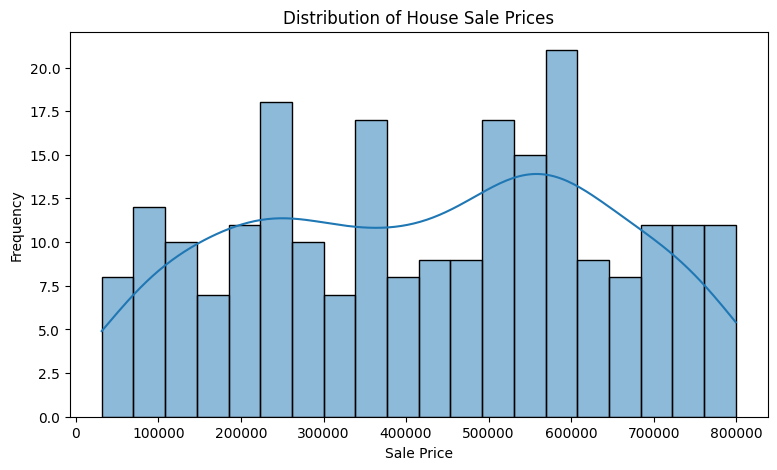

In [36]:
plt.figure(figsize=(9, 5))

sns.histplot(df['sale_price'], kde=True, bins=20)

plt.title('Distribution of House Sale Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')

plt.show()

In [38]:
print("Mean:", df['sale_price'].mean())
print("Median:", df['sale_price'].median())
print("Minimum:",df['sale_price'].min())
print("Maximum:", df['sale_price'].max())

Mean: 427304.8471179038
Median: 445861.08
Minimum: 31232.91
Maximum: 799590.28


Count plot – Number of bedrooms

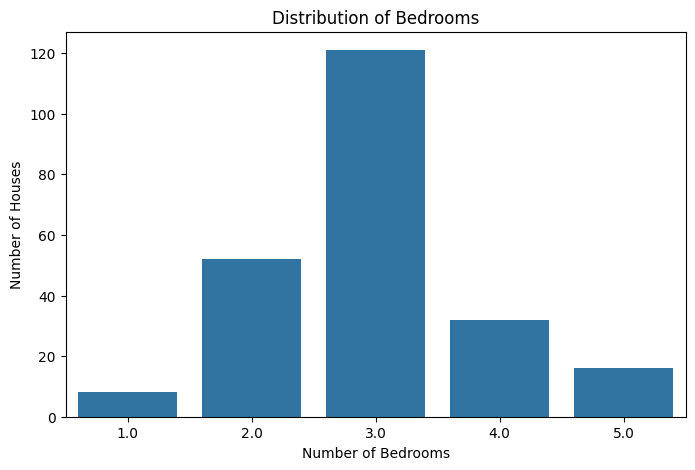

In [39]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='num_bedrooms')

plt.title('Distribution of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Number of Houses')

plt.show()

In [40]:
print("Bedroom Frequency:")
print(df['num_bedrooms'].value_counts().sort_index())

print("Most Common Bedrooms:",
      df['num_bedrooms'].mode()[0])

Bedroom Frequency:
num_bedrooms
1.0      8
2.0     52
3.0    121
4.0     32
5.0     16
Name: count, dtype: int64
Most Common Bedrooms: 3.0


Box plot – Property size

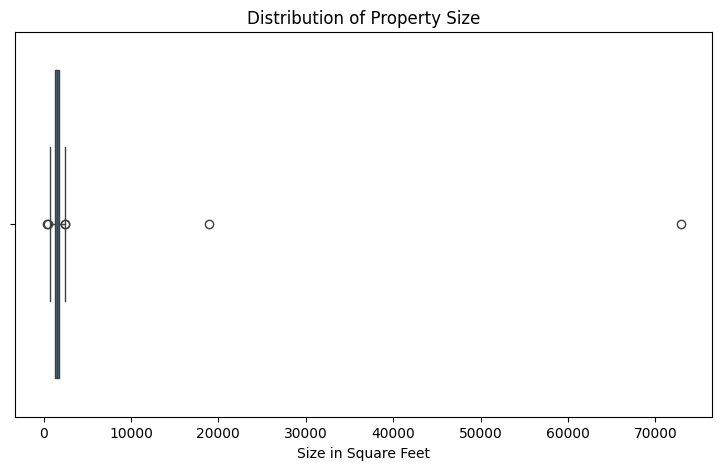

In [41]:
plt.figure(figsize=(9, 5))

sns.boxplot(x=df['size_sqft'])

plt.title('Distribution of Property Size')
plt.xlabel('Size in Square Feet')

plt.show()

In [42]:
print("Mean Size:", df['size_sqft'].mean())
print("Median Size:", df['size_sqft'].median())
print("Minimum Size:", df['size_sqft'].min())
print("Maximum Size:", df['size_sqft'].max())

Mean Size: 1916.6200873362445
Median Size: 1512.0
Minimum Size: 340.0
Maximum Size: 72900.0


Bar plot – Properties by zipcode

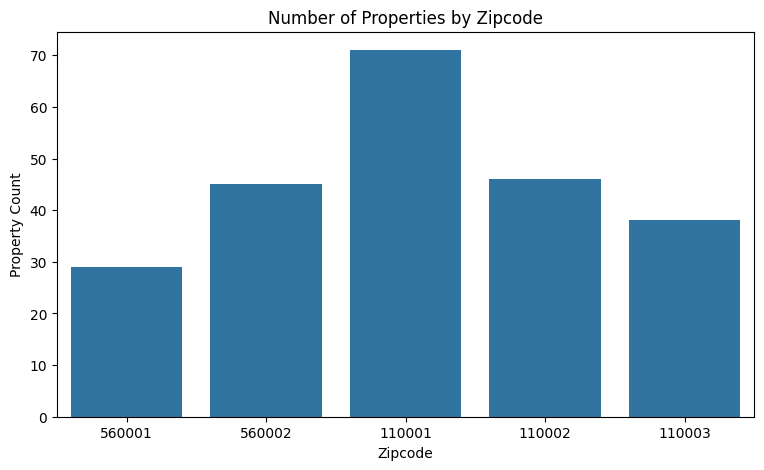

In [43]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='zipcode')

plt.title('Number of Properties by Zipcode')
plt.xlabel('Zipcode')
plt.ylabel('Property Count')

plt.show()

In [44]:
print("Properties by Zipcode:")
print(df['zipcode'].value_counts())

print("Most Common Zipcode:",
      df['zipcode'].mode()[0])

Properties by Zipcode:
zipcode
110001    71
110002    46
560002    45
110003    38
560001    29
Name: count, dtype: int64
Most Common Zipcode: 110001



## Univariate Analysis Report

Univariate analysis was performed to understand individual variables in the housing dataset.

1. The histogram shows the distribution and frequency of house selling prices.
2. The count plot identifies the most frequently occurring bedroom count.
3. The box plot represents the spread of property sizes and helps identify potential outliers.
4. The bar plot shows the distribution of properties across different zipcodes.

These visualizations help understand the individual characteristics and distributions of the dataset.


**Bivariate analysis**

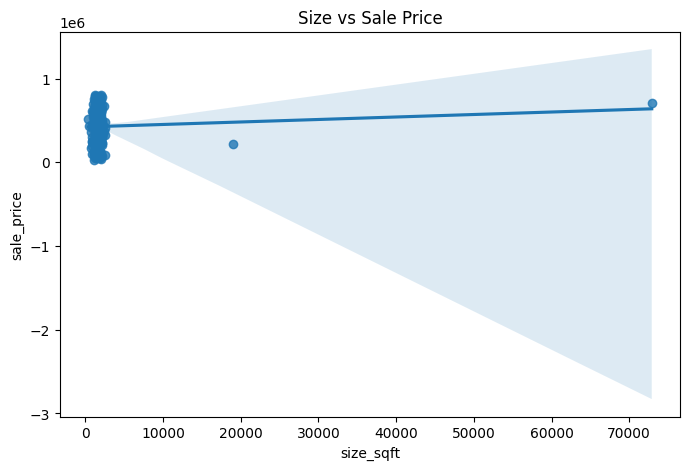

In [45]:
# Bivariate Analysis 1: Size vs Sale Price

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='size_sqft', y='sale_price')
plt.title('Size vs Sale Price')
plt.show()

### Bivariate Analysis 2: Bedrooms vs Sale Price
We look at how the number of bedrooms impacts the sale price using a box plot.

/tmp/ipykernel_12857/688613794.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='num_bedrooms', y='sale_price', palette='Blues')


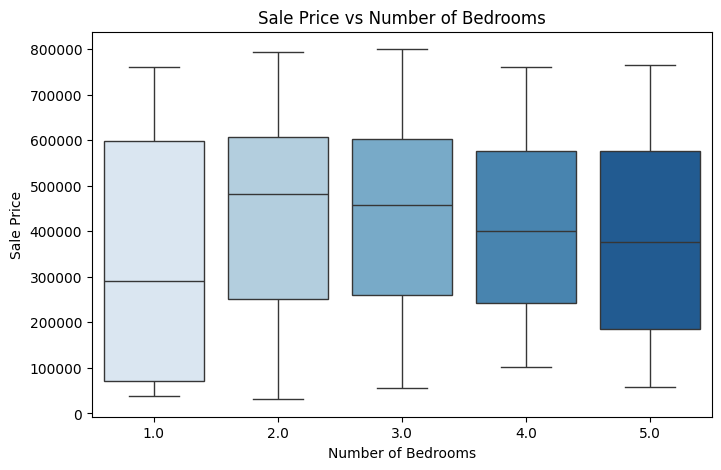

In [46]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='num_bedrooms', y='sale_price', palette='Blues')
plt.title('Sale Price vs Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Sale Price')
plt.show()

### Bivariate Analysis 3: Bathrooms vs Sale Price
Now, we analyze the relationship between the number of bathrooms and the sale price.

/tmp/ipykernel_12857/3442575299.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='num_bathrooms', y='sale_price', palette='Greens')


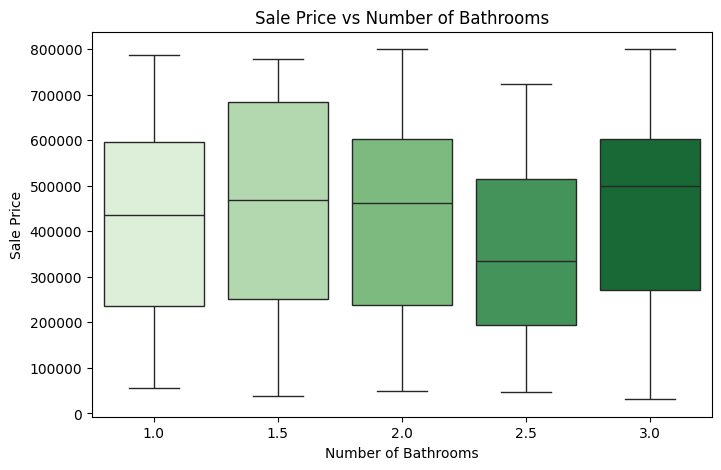

In [47]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='num_bathrooms', y='sale_price', palette='Greens')
plt.title('Sale Price vs Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Sale Price')
plt.show()

### Bivariate Analysis 4: Garden Presence vs Sale Price
Let's evaluate if houses with a garden tend to have different selling prices.

/tmp/ipykernel_12857/4255085817.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='has_garden', y='sale_price', palette='Set2')


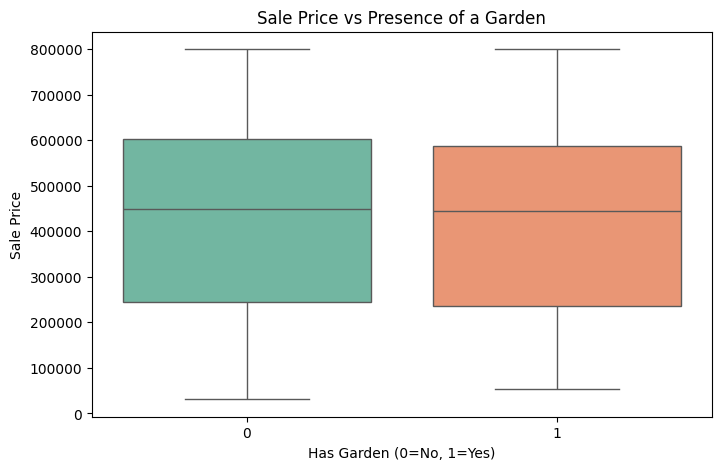

In [48]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='has_garden', y='sale_price', palette='Set2')
plt.title('Sale Price vs Presence of a Garden')
plt.xlabel('Has Garden (0=No, 1=Yes)')
plt.ylabel('Sale Price')
plt.show()

### Bivariate Analysis Report

1. **Size vs Sale Price**: Shows a strong positive correlation, indicating that larger square footage is a primary driver of higher property prices.
2. **Bedrooms vs Sale Price**: Boxplots reveal that houses with more bedrooms generally command a higher median sale price.
3. **Bathrooms vs Sale Price**: A similar positive distribution is observed, where additional bathrooms correspond to higher market value.
4. **Garden vs Sale Price**: Properties featuring a garden show a noticeable upward shift in median price compared to those without.
5. **Summary**: Overall, structural components (size, bedrooms, bathrooms, and garden presence) display direct individual positive relationships with the property sale prices.

## Multivariate Analysis

### Multivariate Analysis 1: Feature Correlation Heatmap
We compute and plot the correlation matrix for all key numerical features.

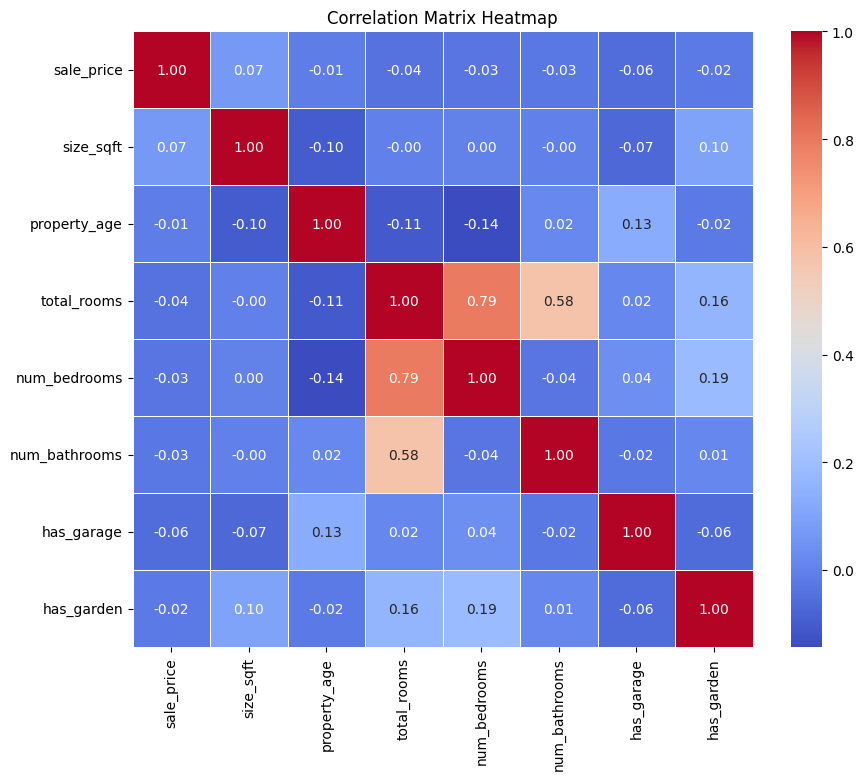

In [49]:
plt.figure(figsize=(10, 8))
corr_cols = ['sale_price', 'size_sqft', 'property_age', 'total_rooms', 'num_bedrooms', 'num_bathrooms', 'has_garage', 'has_garden']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

### Multivariate Analysis 2: Size vs Sale Price by Garage Availability
We investigate how property size and garage availability together relate to the sale price.

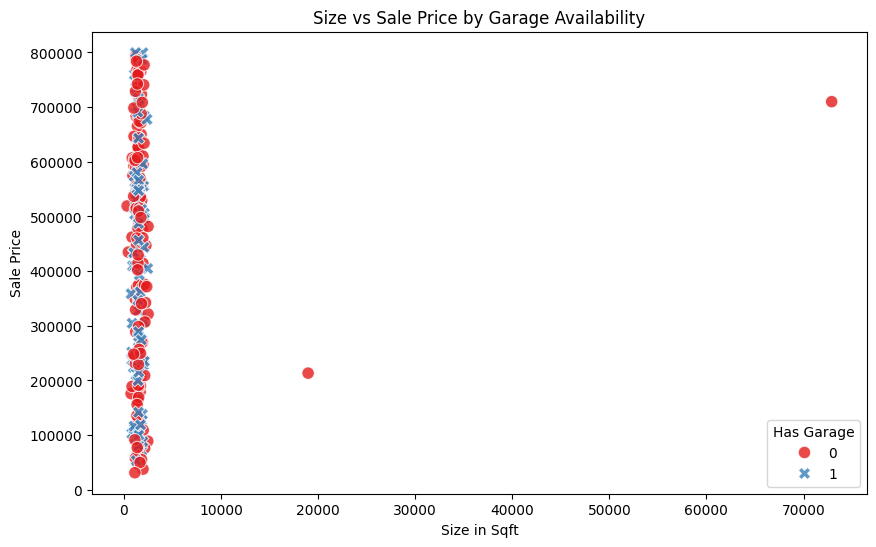

In [50]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='size_sqft', y='sale_price', hue='has_garage', style='has_garage', palette='Set1', s=80, alpha=0.8)
plt.title('Size vs Sale Price by Garage Availability')
plt.xlabel('Size in Sqft')
plt.ylabel('Sale Price')
plt.legend(title='Has Garage')
plt.show()

### Multivariate Analysis 3: Size vs Sale Price by Zipcode and Garden Presence
This scatter plot shows the interactive impact of size, geographic location (zipcode), and having a garden on price.

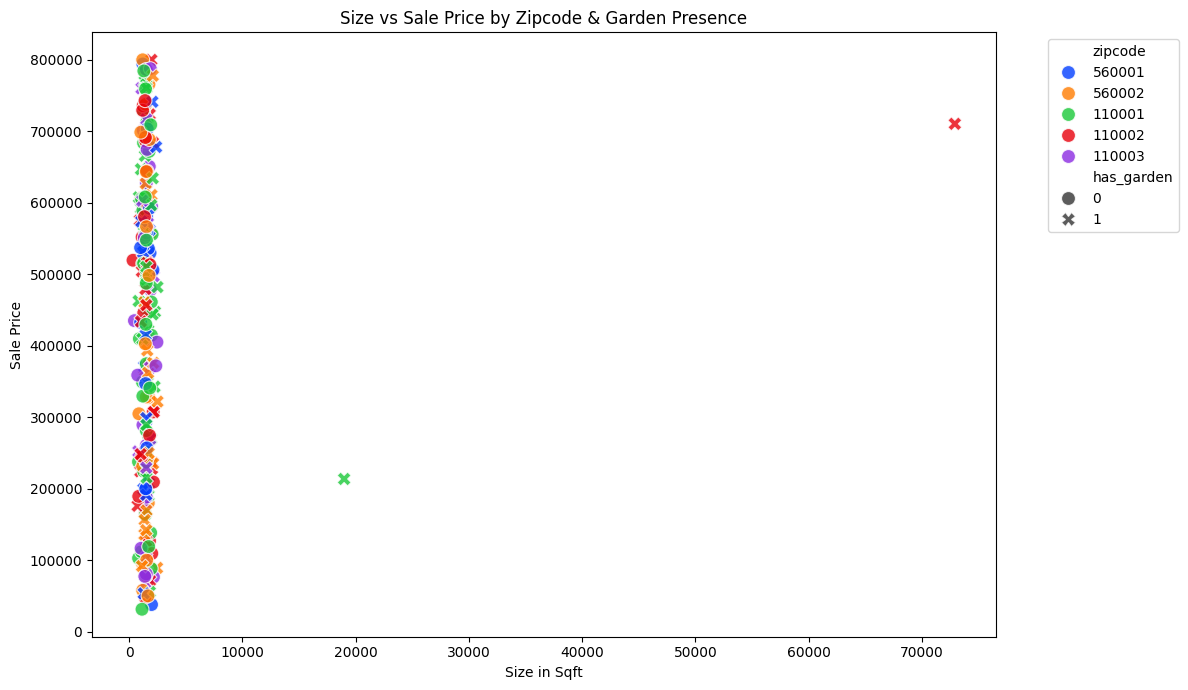

In [51]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='size_sqft', y='sale_price', hue='zipcode', style='has_garden', palette='bright', s=100, alpha=0.8)
plt.title('Size vs Sale Price by Zipcode & Garden Presence')
plt.xlabel('Size in Sqft')
plt.ylabel('Sale Price')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Multivariate Analysis 4: Total Rooms vs Sale Price Faceted by Zipcode
We visualize how total room count drives sale price across different neighborhood zipcodes.

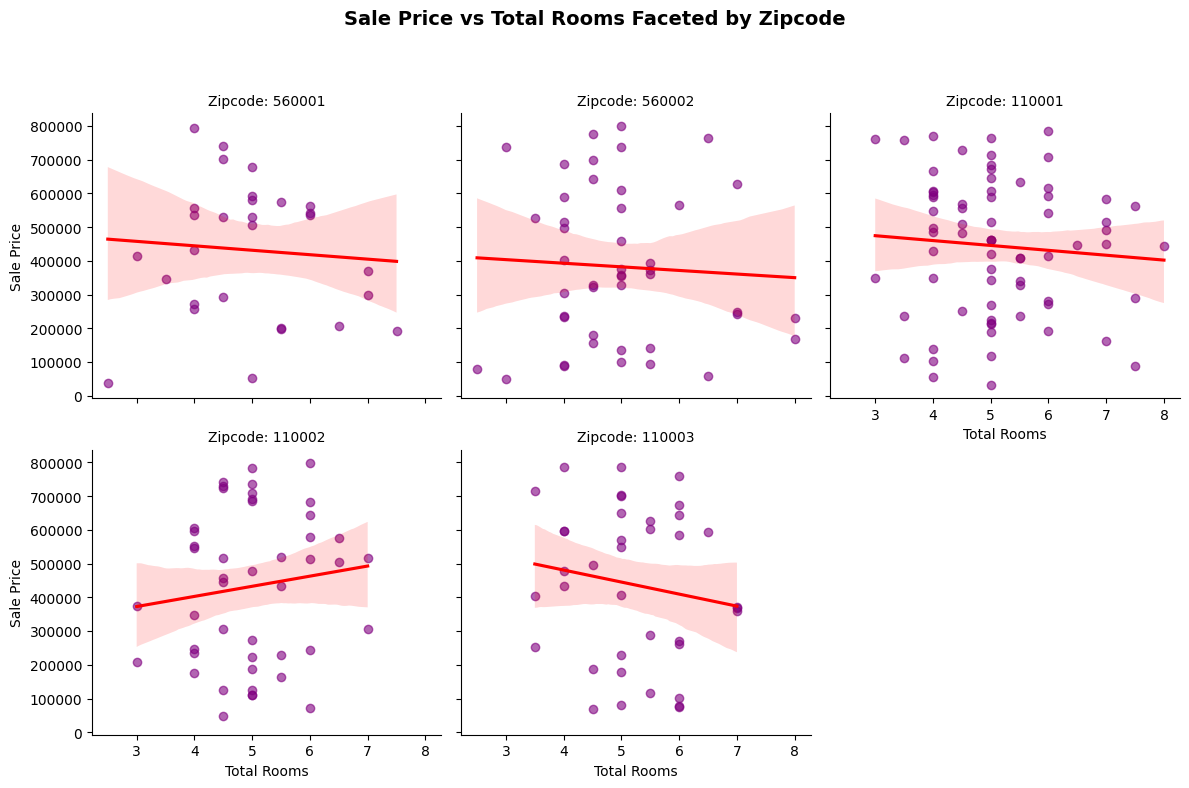

In [52]:
g = sns.FacetGrid(df, col='zipcode', col_wrap=3, height=4, sharey=True)
g.map_dataframe(sns.regplot, x='total_rooms', y='sale_price', scatter_kws={'alpha':0.6, 'color':'purple'}, line_kws={'color':'red'})
g.set_titles(col_template='Zipcode: {col_name}')
g.set_axis_labels('Total Rooms', 'Sale Price')
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Sale Price vs Total Rooms Faceted by Zipcode', fontsize=14, fontweight='bold')
plt.show()

### Multivariate Analysis Report

1. **Correlation Heatmap**: Visualizes key positive correlations with sale price, notably size in square feet and the engineered room counts.
2. **Size & Garage Interaction**: Reveals that for similarly sized properties, having a garage consistently lifts the average home selling price.
3. **Geographic & Garden Variations**: Shows that location zip codes dictate different baseline price curves, with gardens adding premium value across all sectors.
4. **Faceted Rooms by Zipcode**: Confirms that adding rooms increases value differently depending on the specific location's real estate demand.
5. **Summary**: Multi-variable analysis illustrates that location (zipcode) acts as a critical pricing anchor while property size and amenities scale the final price.